<a href="https://colab.research.google.com/github/sanchitha22/FDS-LabExperiments/blob/main/exp16.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Analyzing target column: 'TrafficCount'


/tmp/ipykernel_1536/3570693161.py:33: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  data = data.resample('H').mean()


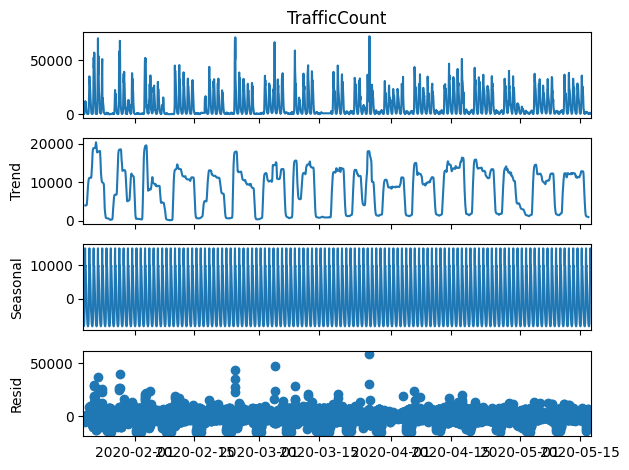

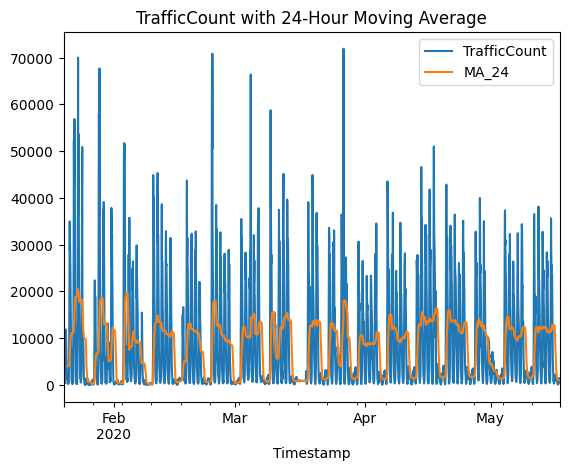

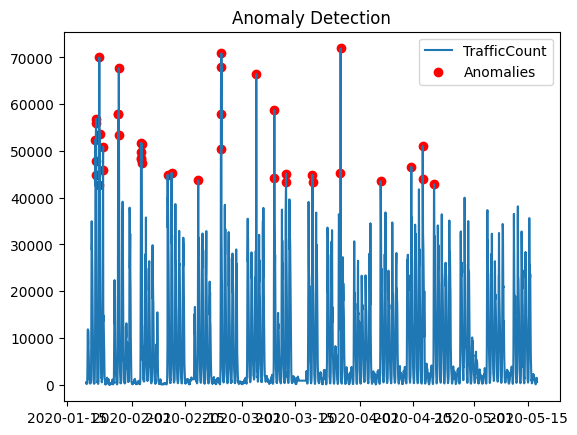

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

# Load dataset and clean column names
data = pd.read_csv('/content/web_traffic.csv')
data.columns = data.columns.str.strip()

# Find the date column dynamically (case-insensitive search for 'date' or 'timestamp')
date_col = [col for col in data.columns if col.lower() in ['date', 'timestamp']]
if date_col:
    date_col = date_col[0]
    data[date_col] = pd.to_datetime(data[date_col])
    data.set_index(date_col, inplace=True)
else:
    raise KeyError(f"Could not find a date or timestamp column. Available columns: {list(data.columns)}")

# Determine target column: use 'TrafficCount' or other numeric columns
target_col = 'TrafficCount'
if target_col not in data.columns:
    available_numeric = data.select_dtypes(include=['number']).columns
    if len(available_numeric) > 0:
        target_col = available_numeric[0]
    else:
        target_col = data.columns[0]

print(f"Analyzing target column: '{target_col}'")

# Ensure the target column contains float values
data[target_col] = data[target_col].astype(float)

# Resample to hourly intervals ('H') to resolve duplicate or irregular frequency issues
data = data.resample('H').mean()

# Fill any missing values resulting from resampling
data[target_col] = data[target_col].ffill().bfill()

# Time Series Decomposition
# We specify period=24 to capture the daily seasonality (24 hours)
decomposition = seasonal_decompose(data[target_col], model='additive', period=24)
decomposition.plot()
plt.show()

# Moving Average (using a 24-hour window)
data['MA_24'] = data[target_col].rolling(window=min(24, len(data))).mean()
data[[target_col, 'MA_24']].plot()
plt.title(f'{target_col} with 24-Hour Moving Average')
plt.show()

# Anomaly Detection
data['Z_Score'] = (data[target_col] - data[target_col].mean()) / data[target_col].std()
anomalies = data[data['Z_Score'].abs() > 3]

plt.plot(data.index, data[target_col], label=target_col)
if not anomalies.empty:
    plt.scatter(anomalies.index, anomalies[target_col], color='red', label='Anomalies')
plt.legend()
plt.title('Anomaly Detection')
plt.show()